In [1]:
# Cell 1
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RETRIEVER_PATH = PROJECT_ROOT / "src" / "retrieval" / "retriever.py"
EMBEDDER_PATH = PROJECT_ROOT / "src" / "embeddings" / "embedder.py"
GENERATOR_PATH = PROJECT_ROOT / "src" / "generation" / "answer_generator.py"

EVAL_DIR = PROJECT_ROOT / "eval"
RESULTS_DIR = EVAL_DIR / "results"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Retriever exists:", RETRIEVER_PATH.exists())
print("Embedder exists:", EMBEDDER_PATH.exists())
print("Answer generator exists:", GENERATOR_PATH.exists())
print("Evaluation directory exists:", EVAL_DIR.exists())
print("Results directory:", RESULTS_DIR)

Project root: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant
Retriever exists: True
Embedder exists: True
Answer generator exists: True
Evaluation directory exists: True
Results directory: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results


In [2]:
# Cell 2
print("EXISTING EVALUATION FILES")
print("=" * 60)

for folder in [EVAL_DIR, OUTPUT_DIR]:
    if not folder.exists():
        continue

    print(f"\nFolder: {folder.relative_to(PROJECT_ROOT)}")

    for path in sorted(folder.rglob("*")):
        if path.is_file() and path.suffix.lower() in {
            ".json", ".csv", ".yaml", ".yml"
        }:
            try:
                relative_path = path.relative_to(PROJECT_ROOT)
                size_kb = round(path.stat().st_size / 1024, 2)
                print(f"{relative_path} ({size_kb} KB)")
            except OSError:
                pass

EXISTING EVALUATION FILES

Folder: eval
eval\results\notebook04_retrieval_evaluation.json (0.37 KB)
eval\results\notebook04_retrieval_metrics.csv (0.15 KB)
eval\results\notebook05_architecture_evaluation.json (1.61 KB)
eval\results\notebook05_architecture_metrics.csv (0.23 KB)
eval\results\notebook06_architecture_consistency.json (0.63 KB)
eval\results\notebook06_component_evaluation.json (0.39 KB)
eval\results\notebook06_consolidated_report.json (4.08 KB)
eval\results\notebook06_data_quality_report.json (0.59 KB)
eval\results\notebook06_dependency_evaluation.json (0.41 KB)
eval\results\notebook06_eda_summary.json (0.32 KB)
eval\results\notebook06_entity_profile.csv (0.19 KB)
eval\results\notebook06_interface_port_evaluation.json (0.71 KB)
eval\results\notebook06_interface_port_profile.json (0.79 KB)

Folder: outputs
outputs\comparison\revision_comparison_latest.json (14.53 KB)
outputs\comparison\revision_comparison_test.json (12.69 KB)
outputs\evaluation\architecture_inconsistency_rep

In [3]:
# Cell 3
print("RETRIEVER SOURCE INSPECTION")
print("=" * 60)

if RETRIEVER_PATH.exists():
    retriever_source = RETRIEVER_PATH.read_text(encoding="utf-8")
    retriever_lines = retriever_source.splitlines()

    print("Total source lines:", len(retriever_lines))
    print("\n".join(
        f"{i + 1:04d}: {line}"
        for i, line in enumerate(retriever_lines[:220])
    ))

    if len(retriever_lines) > 220:
        print("\n... additional lines omitted ...")
else:
    print("Retriever source file not found.")

RETRIEVER SOURCE INSPECTION
Total source lines: 1130
0001: # src/retrieval/retriever.py
0002: 
0003: from pathlib import Path
0004: import json
0005: import re
0006: 
0007: import faiss
0008: import numpy as np
0009: 
0010: from src.embeddings.embedder import ArchitectureEmbedder
0011: 
0012: 
0013: class ArchitectureRetriever:
0014:     """
0015:     Hybrid retrieval over AUTOSAR architecture knowledge.
0016: 
0017:     Supports:
0018:     1. Semantic retrieval using FastEmbed + FAISS
0019:     2. Structured architecture-aware retrieval
0020:     3. Hybrid retrieval
0021:     4. Both legacy and production RAG document formats
0022:     """
0023: 
0024:     def __init__(
0025:         self,
0026:         model_name="BAAI/bge-small-en-v1.5"
0027:     ):
0028: 
0029:         self.embedder = ArchitectureEmbedder(
0030:             model_name=model_name
0031:         )
0032: 
0033:         self.chunks = []
0034:         self.index = None
0035: 
0036:     # =================================

In [4]:
# Cell 4
print("EMBEDDER SOURCE INSPECTION")
print("=" * 60)

if EMBEDDER_PATH.exists():
    embedder_source = EMBEDDER_PATH.read_text(encoding="utf-8")
    embedder_lines = embedder_source.splitlines()

    print("Total source lines:", len(embedder_lines))
    print("\n".join(
        f"{i + 1:04d}: {line}"
        for i, line in enumerate(embedder_lines[:180])
    ))

    if len(embedder_lines) > 180:
        print("\n... additional lines omitted ...")
else:
    print("Embedder source file not found.")

EMBEDDER SOURCE INSPECTION
Total source lines: 86
0001: # src/embeddings/embedder.py
0002: 
0003: from pathlib import Path
0004: import json
0005: 
0006: from fastembed import TextEmbedding
0007: 
0008: 
0009: class ArchitectureEmbedder:
0010:     """
0011:     Generates embeddings for AUTOSAR architecture chunks
0012:     using a lightweight local embedding model.
0013:     """
0014: 
0015:     def __init__(
0016:         self,
0017:         model_name="BAAI/bge-small-en-v1.5"
0018:     ):
0019:         self.model_name = model_name
0020: 
0021:         self.model = TextEmbedding(
0022:             model_name=model_name
0023:         )
0024: 
0025:     def embed_chunks(self, chunks):
0026:         """
0027:         Generate embeddings for chunk content.
0028:         """
0029: 
0030:         texts = [
0031:             chunk["content"]
0032:             for chunk in chunks
0033:         ]
0034: 
0035:         embeddings = list(
0036:             self.model.embed(texts)
0037:         )


In [5]:
# Cell 5
print("RETRIEVAL EVALUATION ARTIFACTS")
print("=" * 60)

candidate_files = []

for folder in [EVAL_DIR, OUTPUT_DIR]:
    if folder.exists():
        for path in folder.rglob("*"):
            if not path.is_file():
                continue

            filename = path.name.lower()

            if any(term in filename for term in [
                "retrieval",
                "evaluation",
                "ground_truth",
                "query",
                "metric"
            ]):
                candidate_files.append(path)

if not candidate_files:
    print("No matching retrieval evaluation files found.")
else:
    for path in sorted(set(candidate_files)):
        print(path.relative_to(PROJECT_ROOT))

RETRIEVAL EVALUATION ARTIFACTS
eval\results\dependency_evaluation.png
eval\results\notebook04_retrieval_evaluation.json
eval\results\notebook04_retrieval_metrics.csv
eval\results\notebook05_architecture_evaluation.json
eval\results\notebook05_architecture_metrics.csv
eval\results\notebook06_component_evaluation.json
eval\results\notebook06_dependency_evaluation.json
eval\results\notebook06_interface_port_evaluation.json
outputs\evaluation\evaluation_summary.json
outputs\evaluation\rag_evaluation_results.json
outputs\reports\architecture_evaluation.json


In [6]:
# Cell 6
RETRIEVAL_EVAL_PATH = (
    RESULTS_DIR / "notebook04_retrieval_evaluation.json"
)

with open(RETRIEVAL_EVAL_PATH, "r", encoding="utf-8") as file:
    retrieval_evaluation = json.load(file)

print("Existing retrieval evaluation loaded.")
print("Top-level structure:", type(retrieval_evaluation).__name__)

if isinstance(retrieval_evaluation, dict):
    print("Available keys:", list(retrieval_evaluation.keys()))

print("\nEvaluation content:")
print(json.dumps(retrieval_evaluation, indent=2, ensure_ascii=False)[:6000])

Existing retrieval evaluation loaded.
Top-level structure: dict
Available keys: ['notebook', 'evaluation_questions', 'query_types_tested', 'top_k_tested', 'retrieval_accuracy', 'mean_precision', 'mean_recall', 'mean_f1', 'citation_coverage', 'unsupported_query_handled']

Evaluation content:
{
  "notebook": "04_retrieval_eval_prompts",
  "evaluation_questions": 5,
  "query_types_tested": 4,
  "top_k_tested": [
    1,
    3,
    5,
    10
  ],
  "retrieval_accuracy": 100.0,
  "mean_precision": 92.0,
  "mean_recall": 100.0,
  "mean_f1": 95.56,
  "citation_coverage": 100.0,
  "unsupported_query_handled": true
}


In [7]:
# Cell 7
RETRIEVAL_METRICS_PATH = (
    RESULTS_DIR / "notebook04_retrieval_metrics.csv"
)

retrieval_metrics_df = pd.read_csv(RETRIEVAL_METRICS_PATH)

print("Retrieval metrics loaded.")
print("Rows:", len(retrieval_metrics_df))
print("Columns:", retrieval_metrics_df.columns.tolist())

display(retrieval_metrics_df.head(10))

Retrieval metrics loaded.
Rows: 5
Columns: ['id', 'top_k', 'precision', 'recall', 'f1']


,id,top_k,precision,recall,f1
0,Q001,5,0.8,1.0,0.888889
1,Q002,5,1.0,1.0,1.000000
2,Q003,5,1.0,1.0,1.000000
3,Q004,5,0.8,1.0,0.888889
4,Q005,5,1.0,1.0,1.000000


In [8]:
# Cell 8
RAG_EVAL_PATH = (
    OUTPUT_DIR / "evaluation" / "rag_evaluation_results.json"
)

with open(RAG_EVAL_PATH, "r", encoding="utf-8") as file:
    rag_evaluation = json.load(file)

print("RAG evaluation results loaded.")

if isinstance(rag_evaluation, dict):
    print("Available keys:", list(rag_evaluation.keys()))

print("\nRAG evaluation preview:")
print(json.dumps(rag_evaluation, indent=2, ensure_ascii=False)[:6000])

RAG evaluation results loaded.

RAG evaluation preview:
[
  {
    "query": "Which component consumes BatteryTemperature?",
    "passed": true,
    "evidence_count": 1,
    "answer": "ThermalController consumed BatteryTemperature. Source: sample_autosar_hld.pdf, Page 4, Section 7 - Signals and Data Flow."
  },
  {
    "query": "Which components depend on BatteryMonitor?",
    "passed": true,
    "evidence_count": 2,
    "answer": "The components that depend on BatteryMonitor are: ThermalController, Dashboard."
  },
  {
    "query": "What interface connects BatteryMonitor and Dashboard?",
    "passed": true,
    "evidence_count": 1,
    "answer": "The interface is BatteryStatusInterface."
  },
  {
    "query": "Which component provides BatteryStatus?",
    "passed": true,
    "evidence_count": 0,
    "answer": "The provided evidence is insufficient to answer this question."
  },
  {
    "query": "What is the functional flow from battery measurement to cooling request?",
    "passed": tru

In [9]:
# Cell 9
EVALUATION_SUMMARY_PATH = (
    OUTPUT_DIR / "evaluation" / "evaluation_summary.json"
)

with open(EVALUATION_SUMMARY_PATH, "r", encoding="utf-8") as file:
    evaluation_summary = json.load(file)

print("Evaluation summary loaded.")

if isinstance(evaluation_summary, dict):
    print("Available keys:", list(evaluation_summary.keys()))

print("\nSummary preview:")
print(json.dumps(evaluation_summary, indent=2, ensure_ascii=False)[:6000])

Evaluation summary loaded.
Available keys: ['rag_evaluation', 'citation_evaluation', 'architecture_validation']

Summary preview:
{
  "rag_evaluation": {
    "total_test_cases": 5,
    "passed": 5,
    "failed": 0,
    "accuracy": 1.0
  },
  "citation_evaluation": {
    "valid_citations": 8,
    "total_evidence_items": 8,
    "citation_coverage": 1.0
  },
  "architecture_validation": {
    "potential_inconsistencies": 2
  }
}


In [10]:
# Cell 10
baseline_inventory = {
    "notebook04_retrieval_evaluation": {
        "path": str(RETRIEVAL_EVAL_PATH.relative_to(PROJECT_ROOT)),
        "exists": RETRIEVAL_EVAL_PATH.exists()
    },
    "notebook04_retrieval_metrics": {
        "path": str(RETRIEVAL_METRICS_PATH.relative_to(PROJECT_ROOT)),
        "exists": RETRIEVAL_METRICS_PATH.exists(),
        "rows": len(retrieval_metrics_df)
    },
    "rag_evaluation_results": {
        "path": str(RAG_EVAL_PATH.relative_to(PROJECT_ROOT)),
        "exists": RAG_EVAL_PATH.exists()
    },
    "evaluation_summary": {
        "path": str(EVALUATION_SUMMARY_PATH.relative_to(PROJECT_ROOT)),
        "exists": EVALUATION_SUMMARY_PATH.exists()
    }
}

print("BASELINE INVENTORY")
print("=" * 55)
print(json.dumps(baseline_inventory, indent=2, ensure_ascii=False))

BASELINE INVENTORY
{
  "notebook04_retrieval_evaluation": {
    "path": "eval\\results\\notebook04_retrieval_evaluation.json",
    "exists": true
  },
  "notebook04_retrieval_metrics": {
    "path": "eval\\results\\notebook04_retrieval_metrics.csv",
    "exists": true,
    "rows": 5
  },
  "rag_evaluation_results": {
    "path": "outputs\\evaluation\\rag_evaluation_results.json",
    "exists": true
  },
  "evaluation_summary": {
    "path": "outputs\\evaluation\\evaluation_summary.json",
    "exists": true
  }
}


In [11]:
# Cell 11
# Summarize the existing RAG evaluation results.

rag_results_df = pd.DataFrame(rag_evaluation)

print("RAG QUERY OUTCOMES")
print("=" * 55)
print("Total evaluation records:", len(rag_results_df))
print("Available fields:", rag_results_df.columns.tolist())

if "passed" in rag_results_df.columns:
    passed_count = int(
        rag_results_df["passed"].fillna(False).astype(bool).sum()
    )
    failed_count = len(rag_results_df) - passed_count

    print("Passed:", passed_count)
    print("Failed:", failed_count)

    if len(rag_results_df) > 0:
        print(
            "Pass rate (%):",
            round(passed_count / len(rag_results_df) * 100, 2)
        )

display(rag_results_df)

RAG QUERY OUTCOMES
Total evaluation records: 5
Available fields: ['query', 'passed', 'evidence_count', 'answer']
Passed: 5
Failed: 0
Pass rate (%): 100.0


,query,passed,evidence_count,answer
0,Which component consumes BatteryTemperature?,True,1,ThermalController consumed BatteryTemperature....
1,Which components depend on BatteryMonitor?,True,2,The components that depend on BatteryMonitor a...
2,What interface connects BatteryMonitor and Das...,True,1,The interface is BatteryStatusInterface.
3,Which component provides BatteryStatus?,True,0,The provided evidence is insufficient to answe...
4,What is the functional flow from battery measu...,True,4,The functional flow is:\nStep 1: BatteryMonito...


In [12]:
# Cell 12
print("EVIDENCE COUNT ANALYSIS")
print("=" * 55)

if "evidence_count" in rag_results_df.columns:
    rag_results_df["evidence_count"] = pd.to_numeric(
        rag_results_df["evidence_count"],
        errors="coerce"
    )

    display(
        rag_results_df[
            ["query", "evidence_count", "passed"]
        ]
        if {"query", "evidence_count", "passed"}.issubset(
            rag_results_df.columns
        )
        else rag_results_df[["evidence_count"]]
    )

    print("\nEvidence count statistics:")
    display(rag_results_df["evidence_count"].describe())

    print(
        "Queries with zero evidence:",
        int((rag_results_df["evidence_count"] == 0).sum())
    )
else:
    print("The RAG results do not contain an evidence_count field.")

EVIDENCE COUNT ANALYSIS


,query,evidence_count,passed
0,Which component consumes BatteryTemperature?,1,True
1,Which components depend on BatteryMonitor?,2,True
2,What interface connects BatteryMonitor and Das...,1,True
3,Which component provides BatteryStatus?,0,True
4,What is the functional flow from battery measu...,4,True



Evidence count statistics:


count    5.000000
mean     1.600000
std      1.516575
min      0.000000
25%      1.000000
50%      1.000000
75%      2.000000
max      4.000000
Name: evidence_count, dtype: float64

Queries with zero evidence: 1


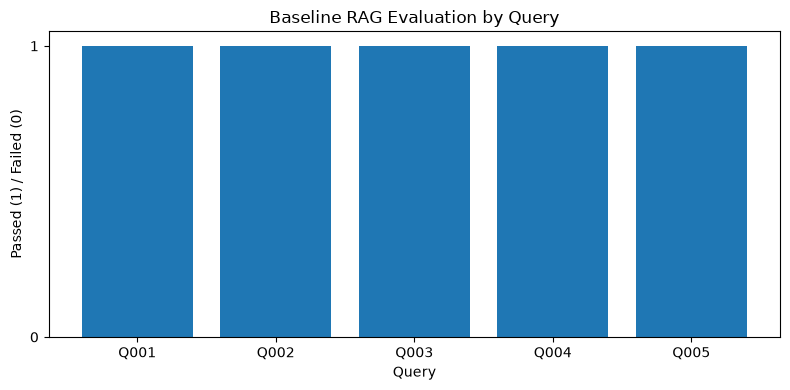

Chart saved to: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook07_baseline_queries.png


In [13]:
# Cell 13
if {"query", "passed"}.issubset(rag_results_df.columns):
    query_labels = [
        f"Q{i + 1:03d}" for i in range(len(rag_results_df))
    ]

    passed_values = (
        rag_results_df["passed"]
        .fillna(False)
        .astype(bool)
        .astype(int)
    )

    plt.figure(figsize=(8, 4))
    plt.bar(query_labels, passed_values)
    plt.title("Baseline RAG Evaluation by Query")
    plt.xlabel("Query")
    plt.ylabel("Passed (1) / Failed (0)")
    plt.yticks([0, 1])
    plt.tight_layout()

    baseline_chart_path = RESULTS_DIR / "notebook07_baseline_queries.png"
    plt.savefig(baseline_chart_path, dpi=150, bbox_inches="tight")
    plt.show()

    print("Chart saved to:", baseline_chart_path)
else:
    print("Required query/pass fields are not available.")

In [14]:
# Cell 14
print("EXISTING RETRIEVAL METRICS")
print("=" * 55)

display(retrieval_metrics_df)

numeric_metrics = [
    column
    for column in ["precision", "recall", "f1"]
    if column in retrieval_metrics_df.columns
]

if numeric_metrics:
    print("\nMean per-query metrics:")
    display(
        retrieval_metrics_df[numeric_metrics]
        .mean()
        .to_frame(name="Mean")
        .round(4)
    )

if "top_k" in retrieval_metrics_df.columns:
    print("\nTop-k values represented in the CSV:")
    print(sorted(retrieval_metrics_df["top_k"].dropna().unique().tolist()))

EXISTING RETRIEVAL METRICS


,id,top_k,precision,recall,f1
0,Q001,5,0.8,1.0,0.888889
1,Q002,5,1.0,1.0,1.000000
2,Q003,5,1.0,1.0,1.000000
3,Q004,5,0.8,1.0,0.888889
4,Q005,5,1.0,1.0,1.000000



Mean per-query metrics:


,Mean
precision,0.9200
recall,1.0000
f1,0.9556



Top-k values represented in the CSV:
[5]


In [15]:
# Cell 15
# Preserve the original aggregate metrics and query-level outcomes.

baseline_snapshot = {
    "notebook": "07_retrieval_experiments",
    "baseline_source": "Notebook 04 existing evaluation",
    "evaluation_questions": int(
        retrieval_evaluation["evaluation_questions"]
    ),
    "query_types_tested": int(
        retrieval_evaluation["query_types_tested"]
    ),
    "top_k_tested": retrieval_evaluation["top_k_tested"],
    "aggregate_metrics": {
        "retrieval_accuracy": retrieval_evaluation["retrieval_accuracy"],
        "mean_precision": retrieval_evaluation["mean_precision"],
        "mean_recall": retrieval_evaluation["mean_recall"],
        "mean_f1": retrieval_evaluation["mean_f1"],
        "citation_coverage": retrieval_evaluation["citation_coverage"],
        "unsupported_query_handled": retrieval_evaluation[
            "unsupported_query_handled"
        ]
    },
    "query_level_records": len(rag_results_df),
    "per_query_metrics_rows": len(retrieval_metrics_df),
    "per_query_top_k_values": (
        sorted(retrieval_metrics_df["top_k"].dropna().unique().tolist())
        if "top_k" in retrieval_metrics_df.columns else []
    ),
    "limitations": [
        "The baseline uses a small evaluation set.",
        "The existing per-query CSV contains five rows at top_k=5.",
        "Aggregate top-k values do not provide per-query metrics at every k.",
        "No retrieval configuration has been changed in this notebook yet."
    ]
}

baseline_snapshot_path = RESULTS_DIR / "notebook07_baseline_snapshot.json"

with open(baseline_snapshot_path, "w", encoding="utf-8") as file:
    json.dump(baseline_snapshot, file, indent=4, ensure_ascii=False)

print("BASELINE SNAPSHOT SAVED")
print("=" * 55)
print(json.dumps(baseline_snapshot, indent=4, ensure_ascii=False))
print("\nSaved to:", baseline_snapshot_path)

BASELINE SNAPSHOT SAVED
{
    "notebook": "07_retrieval_experiments",
    "baseline_source": "Notebook 04 existing evaluation",
    "evaluation_questions": 5,
    "query_types_tested": 4,
    "top_k_tested": [
        1,
        3,
        5,
        10
    ],
    "aggregate_metrics": {
        "retrieval_accuracy": 100.0,
        "mean_precision": 92.0,
        "mean_recall": 100.0,
        "mean_f1": 95.56,
        "citation_coverage": 100.0,
        "unsupported_query_handled": true
    },
    "query_level_records": 5,
    "per_query_metrics_rows": 5,
    "per_query_top_k_values": [
        5
    ],
    "limitations": [
        "The baseline uses a small evaluation set.",
        "The existing per-query CSV contains five rows at top_k=5.",
        "Aggregate top-k values do not provide per-query metrics at every k.",
        "No retrieval configuration has been changed in this notebook yet."
    ]
}

Saved to: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebo

In [16]:
# Cell 16
import ast

def inspect_python_api(file_path):
    if not file_path.exists():
        print(f"File not found: {file_path}")
        return []

    source = file_path.read_text(encoding="utf-8")
    tree = ast.parse(source)
    api_items = []

    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
            api_items.append({
                "type": type(node).__name__,
                "name": node.name,
                "line": node.lineno
            })

    return sorted(api_items, key=lambda item: item["line"])

retriever_api = inspect_python_api(RETRIEVER_PATH)
embedder_api = inspect_python_api(EMBEDDER_PATH)

print("RETRIEVER CLASSES AND FUNCTIONS")
display(pd.DataFrame(retriever_api))

print("\nEMBEDDER CLASSES AND FUNCTIONS")
display(pd.DataFrame(embedder_api))

RETRIEVER CLASSES AND FUNCTIONS


,type,name,line
0,ClassDef,ArchitectureRetriever,13
1,FunctionDef,__init__,24
2,FunctionDef,_normalize_chunk,40
3,FunctionDef,_normalize_chunks,236
4,FunctionDef,build_index,254
5,FunctionDef,search,303
6,FunctionDef,_detect_intent,383
7,FunctionDef,_query_entities,448
8,FunctionDef,structured_search,523
9,FunctionDef,hybrid_search,916



EMBEDDER CLASSES AND FUNCTIONS


,type,name,line
0,ClassDef,ArchitectureEmbedder,9
1,FunctionDef,__init__,15
2,FunctionDef,embed_chunks,25
3,FunctionDef,save_embeddings,41


In [17]:
# Cell 17
print("RETRIEVER IMPLEMENTATION")
print("=" * 60)

retriever_source = RETRIEVER_PATH.read_text(encoding="utf-8")
retriever_lines = retriever_source.splitlines()

for i, line in enumerate(retriever_lines, start=1):
    print(f"{i:04d}: {line}")


print("\nTotal lines:", len(retriever_lines))

RETRIEVER IMPLEMENTATION
0001: # src/retrieval/retriever.py
0002: 
0003: from pathlib import Path
0004: import json
0005: import re
0006: 
0007: import faiss
0008: import numpy as np
0009: 
0010: from src.embeddings.embedder import ArchitectureEmbedder
0011: 
0012: 
0013: class ArchitectureRetriever:
0014:     """
0015:     Hybrid retrieval over AUTOSAR architecture knowledge.
0016: 
0017:     Supports:
0018:     1. Semantic retrieval using FastEmbed + FAISS
0019:     2. Structured architecture-aware retrieval
0020:     3. Hybrid retrieval
0021:     4. Both legacy and production RAG document formats
0022:     """
0023: 
0024:     def __init__(
0025:         self,
0026:         model_name="BAAI/bge-small-en-v1.5"
0027:     ):
0028: 
0029:         self.embedder = ArchitectureEmbedder(
0030:             model_name=model_name
0031:         )
0032: 
0033:         self.chunks = []
0034:         self.index = None
0035: 
0036:     # =========================================================
003

In [18]:
# Cell 18
print("EMBEDDING IMPLEMENTATION")
print("=" * 60)

embedder_source = EMBEDDER_PATH.read_text(encoding="utf-8")
embedder_lines = embedder_source.splitlines()

for i, line in enumerate(embedder_lines, start=1):
    print(f"{i:04d}: {line}")

print("\nTotal lines:", len(embedder_lines))

EMBEDDING IMPLEMENTATION
0001: # src/embeddings/embedder.py
0002: 
0003: from pathlib import Path
0004: import json
0005: 
0006: from fastembed import TextEmbedding
0007: 
0008: 
0009: class ArchitectureEmbedder:
0010:     """
0011:     Generates embeddings for AUTOSAR architecture chunks
0012:     using a lightweight local embedding model.
0013:     """
0014: 
0015:     def __init__(
0016:         self,
0017:         model_name="BAAI/bge-small-en-v1.5"
0018:     ):
0019:         self.model_name = model_name
0020: 
0021:         self.model = TextEmbedding(
0022:             model_name=model_name
0023:         )
0024: 
0025:     def embed_chunks(self, chunks):
0026:         """
0027:         Generate embeddings for chunk content.
0028:         """
0029: 
0030:         texts = [
0031:             chunk["content"]
0032:             for chunk in chunks
0033:         ]
0034: 
0035:         embeddings = list(
0036:             self.model.embed(texts)
0037:         )
0038: 
0039:         retu

In [19]:
# Cell 19
notebook04_path = PROJECT_ROOT / "notebooks" / "04_retrieval_eval_prompts.ipynb"

if notebook04_path.exists():
    with open(notebook04_path, "r", encoding="utf-8") as file:
        notebook04 = json.load(file)

    print("NOTEBOOK 04 CODE-CELL INDEX")
    print("=" * 60)

    for index, cell in enumerate(notebook04.get("cells", [])):
        if cell.get("cell_type") == "code":
            source = "".join(cell.get("source", []))
            first_line = next(
                (line.strip() for line in source.splitlines() if line.strip()),
                "(empty cell)"
            )
            print(f"Cell index {index}: {first_line[:150]}")
else:
    print("Notebook 04 not found at:", notebook04_path)

NOTEBOOK 04 CODE-CELL INDEX
Cell index 0: # Cell 1
Cell index 1: # Cell 2
Cell index 2: # Cell 3
Cell index 3: # Cell 4
Cell index 4: # Cell 5
Cell index 5: # Cell 6
Cell index 6: # Cell 7
Cell index 7: # Cell 8
Cell index 8: # Cell 9
Cell index 9: # Cell 10
Cell index 10: # Cell 11
Cell index 11: # Cell 12
Cell index 12: # Cell 13
Cell index 13: # Cell 14
Cell index 14: # Cell 15
Cell index 15: # Cell 16
Cell index 16: # Cell 17
Cell index 17: # Cell 18
Cell index 18: # Cell 19
Cell index 19: # Cell 20
Cell index 20: # Cell 21
Cell index 21: # Cell 22
Cell index 22: # Cell 23
Cell index 23: # Cell 24
Cell index 24: # Cell 25
Cell index 25: # Cell 26
Cell index 26: # Cell 26
Cell index 27: # Cell 27
Cell index 28: # Cell 28
Cell index 29: # Cell 29
Cell index 30: # Cell 30
Cell index 31: # Cell 31
Cell index 32: # Cell 32
Cell index 33: # Cell 33
Cell index 34: # Cell 34
Cell index 35: # Cell 35
Cell index 36: # Cell 36
Cell index 37: # Cell 37
Cell index 38: # Cell 38
Cell index 39: #

In [20]:
# Cell 20
inspection_summary = {
    "notebook": "07_retrieval_experiments",
    "retriever_file": str(RETRIEVER_PATH),
    "embedder_file": str(EMBEDDER_PATH),
    "notebook04_file": str(notebook04_path),
    "retriever_api": retriever_api,
    "embedder_api": embedder_api,
    "retriever_source_lines": len(retriever_lines),
    "embedder_source_lines": len(embedder_lines),
    "notebook04_exists": notebook04_path.exists()
}

inspection_path = RESULTS_DIR / "notebook07_implementation_inspection.json"

with open(inspection_path, "w", encoding="utf-8") as file:
    json.dump(inspection_summary, file, indent=4, ensure_ascii=False)

print("IMPLEMENTATION INSPECTION SAVED")
print("=" * 60)
print("Retriever API items:", len(retriever_api))
print("Embedder API items:", len(embedder_api))
print("Notebook 04 exists:", notebook04_path.exists())
print("Saved to:", inspection_path)

IMPLEMENTATION INSPECTION SAVED
Retriever API items: 12
Embedder API items: 4
Notebook 04 exists: True
Saved to: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook07_implementation_inspection.json
